# 04 · Expression — EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: with **Gate 2 = NO-GO / Gate 3 = NA** the branching-only `04_correlation` and
`05_modules` notebooks are **not** produced — per §6 the unconditional EMT-TF expression step is the
final notebook and follows signatures directly as 04.)*

The EMT-TF overlay is produced regardless of the gate outcome. Per the **derive-don't-inherit**
mandate we do not inherit Puram's SNAI1/ZEB1 pair: we score a candidate EMT-TF panel — the canonical
Snail/Zeb/Twist factors **plus the mesenchymal / neural-crest FOXC and PRRX families** (the Kürten
EMT-TF lesson) — along *this* pseudotime axis and let the data choose the most end-specific factor
at each end, gated on a 3% detectable-expression floor. Only bona-fide transcription factors are
shown (no VIM/other mesenchymal markers). Deliverable: `expression.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load the rooted, signature-scored manifold
The expression overlay is drawn on the pseudotime-ordered manifold (built end-to-end in 01–03 from
raw). Reading `signatures.h5ad` keeps the layout and pseudotime identical to the other deliverables;
the raw counts needed for the TF panel are the same `adata.X`.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house orientation
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime', round(float(t.min()),2), '->', round(float(t.max()),2))

cells: 7945 | pseudotime 0.0 -> 7.83


### Derive the end-specific EMT-TFs (data-driven)
For each candidate TF: fraction of cells expressing it, mean expression in the early (root) vs late
pseudotime tercile, and Spearman correlation with pseudotime. Most negative correlation
(sufficiently expressed) marks the root end; most positive marks the terminus. Factors below a 3%
expression floor are too sparse to overlay.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; rho,p = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t']).sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\nderived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus)')

    TF  frac_expr  mean_early  mean_late  rho_vs_t
 FOXC2      0.002       0.001      0.000    -0.009
  ZEB1      0.088       0.033      0.040     0.005
 PRRX2      0.039       0.011      0.016     0.015
TWIST1      0.008       0.002      0.004     0.016
TWIST2      0.000       0.000      0.000     0.027
 SNAI1      0.023       0.007      0.012     0.031
 PRRX1      0.022       0.006      0.011     0.034
 FOXC1      0.171       0.065      0.110     0.045
  ZEB2      0.058       0.017      0.032     0.046
 SNAI2      0.093       0.017      0.091     0.181

derived pair: ZEB1 (early/root) <-> SNAI2 (late/terminus)


### EMT-TF expression overlay (deliverable)
House style: `figsize=(3.5,1.5)`, house orientation, `size=30`, **categorical** overlay of
thresholded expressers on a grey manifold (binding style — not a continuous colormap). Draw order by
abundance (more widely-expressed factor first, sparser on top) so neither marker is occluded. Each
factor is thresholded at the upper quartile of expression among its expressing cells; display cutoff
set so the scale is not outlier-dominated.

overlay thresholds (upper quartile among expressers): {'ZEB1': 0.603, 'SNAI2': 0.73} | cells shown: {'ZEB1': 175, 'SNAI2': 184}
ZEB1: 8.8% expressing; 175 shown, mean pseudotime of shown = 0.55 (all cells 0.46)
SNAI2: 9.3% expressing; 184 shown, mean pseudotime of shown = 0.74 (all cells 0.46)
saved expression.pdf


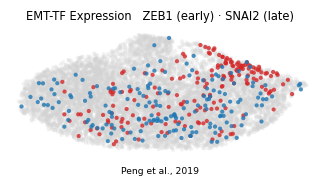

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf, late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) · {late_tf} (late)', size=7.5)
ax.text(.5,-.14,'Peng et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown, '
          f'mean pseudotime of shown = {tn[m].mean():.2f} (all cells {tn.mean():.2f})')
print('saved expression.pdf')